# Fraud Detection — Model Training & Evaluation

Fits **XGBoost**, **Decision Tree**, and **Random Forest** on the preprocessed data.

### Evaluation Metrics
| Metric | Why |
|--------|-----|
| **Accuracy** | Overall correctness (but misleading with 0.56% fraud rate) |
| **Precision** | Of predicted frauds, how many are actually fraud? |
| **Recall** | Of actual frauds, how many did we catch? |
| **F1 Score** | Harmonic mean of precision & recall |
| **AUC-ROC** | Ability to distinguish fraud from non-fraud across all thresholds |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

SEED = 42

## 1. Load Preprocessed Data

Loading from the `preprocessed_data/` directory created by the preprocessing notebook.

In [2]:
DATA_DIR = "preprocessed_data"

X_train = pd.read_csv(f"{DATA_DIR}/X_train.csv")
X_test = pd.read_csv(f"{DATA_DIR}/X_test.csv")
y_train = pd.read_csv(f"{DATA_DIR}/y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}/y_test.csv").squeeze()

print(f"Train: {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"Test:  {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"\nFraud rate — Train: {y_train.mean():.3%} | Test: {y_test.mean():.3%}")
print(f"\nFeature columns: {list(X_train.columns)}")

Train: 739,801 rows x 97 features
Test:  184,951 rows x 97 features

Fraud rate — Train: 0.464% | Test: 0.464%

Feature columns: ['log__amt', 'log__city_pop', 'num__unix_time', 'num__transaction_velocity', 'num__lat', 'num__long', 'num__merch_lat', 'num__merch_long', 'num__age', 'ord__income_band', 'ord__education', 'ord__merchant_size', 'ohe__mcc_4722', 'ohe__mcc_4900', 'ohe__mcc_5311', 'ohe__mcc_5411', 'ohe__mcc_5712', 'ohe__mcc_5812', 'ohe__mcc_5912', 'ohe__mcc_5945', 'ohe__mcc_5999', 'ohe__mcc_7230', 'ohe__state_AK', 'ohe__state_AL', 'ohe__state_AR', 'ohe__state_AZ', 'ohe__state_CA', 'ohe__state_CO', 'ohe__state_CT', 'ohe__state_DC', 'ohe__state_FL', 'ohe__state_GA', 'ohe__state_HI', 'ohe__state_IA', 'ohe__state_ID', 'ohe__state_IL', 'ohe__state_IN', 'ohe__state_KS', 'ohe__state_KY', 'ohe__state_LA', 'ohe__state_MA', 'ohe__state_MD', 'ohe__state_ME', 'ohe__state_MI', 'ohe__state_MN', 'ohe__state_MO', 'ohe__state_MS', 'ohe__state_MT', 'ohe__state_NC', 'ohe__state_ND', 'ohe__state_NE

## 2. Define Models

Using `scale_pos_weight` (XGBoost) and `class_weight='balanced'` (sklearn) to handle the severe class imbalance (0.56% fraud).

In [3]:
# Calculate class imbalance ratio for XGBoost
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"Class imbalance ratio: {scale_pos_weight:.1f}:1 (non-fraud:fraud)")

models = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        min_samples_leaf=20,
        random_state=SEED,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        max_depth=15,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=SEED,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        use_label_encoder=False,
        n_jobs=-1,
        random_state=SEED,
    ),
}

print(f"\nModels to train: {list(models.keys())}")

Class imbalance ratio: 214.6:1 (non-fraud:fraud)

Models to train: ['Decision Tree', 'Random Forest', 'XGBoost']


## 3. Train & Evaluate All Models

In [4]:
results = []
trained_models = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"{'='*60}")

    # --- Fit ---
    model.fit(X_train, y_train)
    trained_models[name] = model

    # --- Predict ---
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # --- Evaluate ---
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc_roc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "AUC-ROC": auc_roc,
    })

    # --- Print classification report ---
    print(f"\n{name} — Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"]))

print("\nAll models trained.")


Training: Decision Tree

Decision Tree — Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.82      0.90    184093
       Fraud       0.02      0.75      0.04       858

    accuracy                           0.82    184951
   macro avg       0.51      0.79      0.47    184951
weighted avg       0.99      0.82      0.90    184951


Training: Random Forest

Random Forest — Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.96      0.98    184093
       Fraud       0.08      0.82      0.15       858

    accuracy                           0.96    184951
   macro avg       0.54      0.89      0.56    184951
weighted avg       0.99      0.96      0.97    184951


Training: XGBoost


/Users/hayansaab/Library/Python/3.9/lib/python/site-packages/xgboost/core.py:158: UserWarning: [16:25:53] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



XGBoost — Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00    184093
       Fraud       0.34      0.93      0.50       858

    accuracy                           0.99    184951
   macro avg       0.67      0.96      0.75    184951
weighted avg       1.00      0.99      0.99    184951


All models trained.


## 4. Results Comparison Table

In [5]:
results_df = pd.DataFrame(results).set_index("Model")

# Format as percentages for readability
styled = results_df.style.format("{:.4f}").background_gradient(
    cmap="RdYlGn", subset=["Precision", "Recall", "F1 Score", "AUC-ROC"]
).set_caption("Model Comparison — Fraud Detection")

print("=== Model Comparison ===")
print(results_df.to_string())
print()

# Highlight best model per metric
print("=== Best Model per Metric ===")
for col in ["Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]:
    best = results_df[col].idxmax()
    print(f"  {col:12s}: {best} ({results_df.loc[best, col]:.4f})")

styled

=== Model Comparison ===
               Accuracy  Precision    Recall  F1 Score   AUC-ROC
Model                                                           
Decision Tree  0.821796   0.019230  0.748252  0.037497  0.868131
Random Forest  0.955853   0.080684  0.819347  0.146902  0.970357
XGBoost        0.991457   0.344128  0.928904  0.502205  0.992495

=== Best Model per Metric ===
  Accuracy    : XGBoost (0.9915)
  Precision   : XGBoost (0.3441)
  Recall      : XGBoost (0.9289)
  F1 Score    : XGBoost (0.5022)
  AUC-ROC     : XGBoost (0.9925)


,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Model,,,,,
Decision Tree,0.8218,0.0192,0.7483,0.0375,0.8681
Random Forest,0.9559,0.0807,0.8193,0.1469,0.9704
XGBoost,0.9915,0.3441,0.9289,0.5022,0.9925


## 5. Visualization

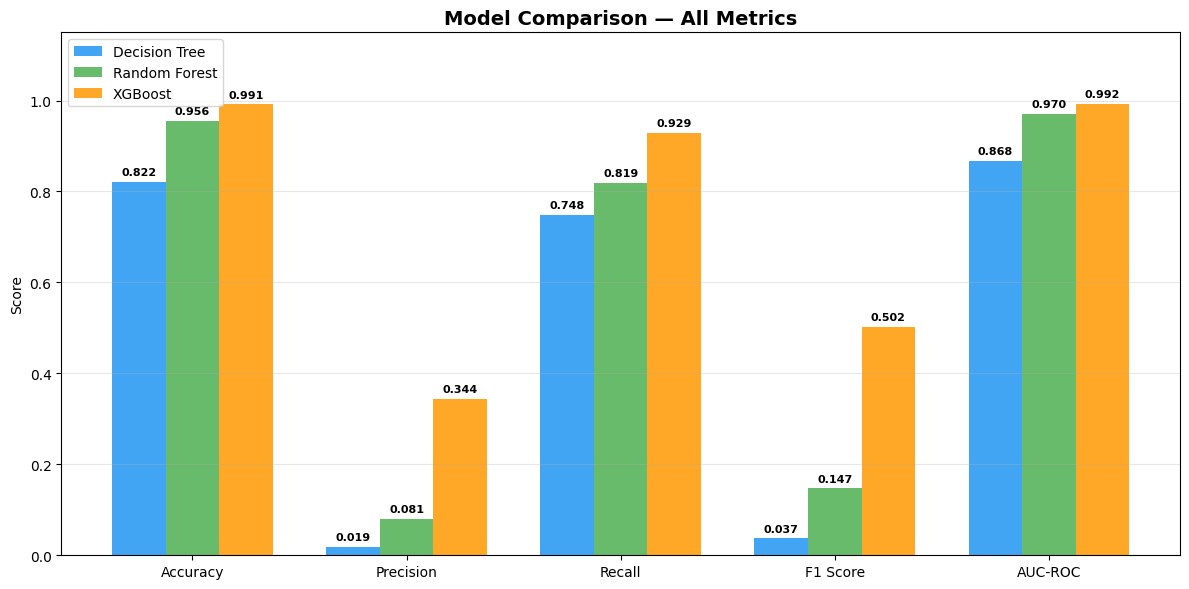

In [6]:
# ============================================================
# Bar chart: all metrics side by side
# ============================================================

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]
x = np.arange(len(metrics))
width = 0.25
colors = ["#2196F3", "#4CAF50", "#FF9800"]

fig, ax = plt.subplots(figsize=(12, 6))

for i, (model_name, row) in enumerate(results_df.iterrows()):
    values = [row[m] for m in metrics]
    bars = ax.bar(x + i * width, values, width, label=model_name, color=colors[i], alpha=0.85)
    # Add value labels on bars
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{val:.3f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_ylabel("Score")
ax.set_title("Model Comparison — All Metrics", fontsize=14, fontweight="bold")
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

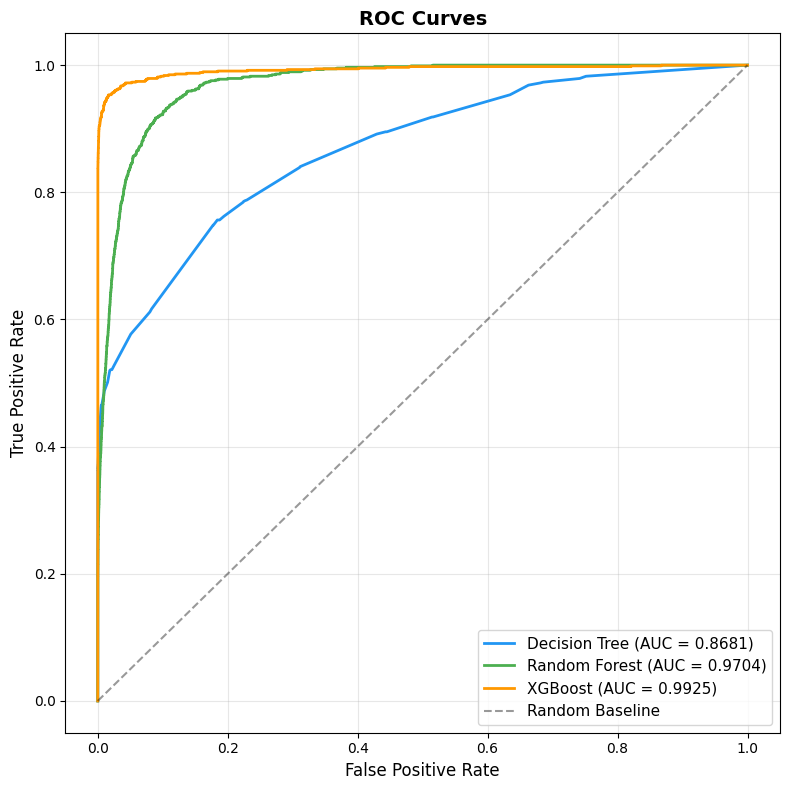

In [7]:
# ============================================================
# ROC Curves — all models
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))

for i, (name, model) in enumerate(trained_models.items()):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=colors[i], linewidth=2)

ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random Baseline")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curves", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

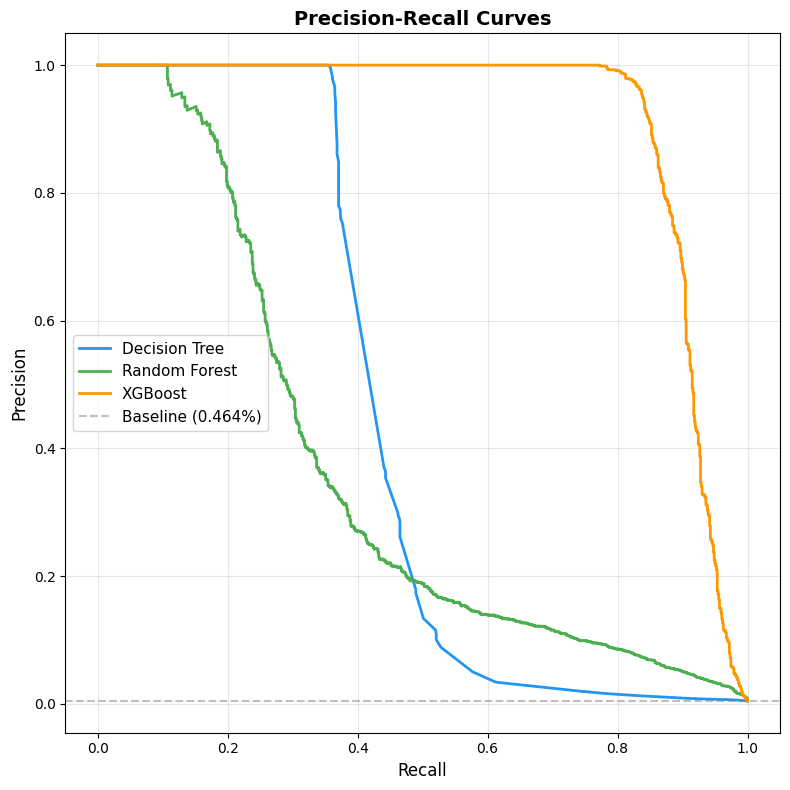

In [8]:
# ============================================================
# Precision-Recall Curves — critical for imbalanced data
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))

for i, (name, model) in enumerate(trained_models.items()):
    y_prob = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ax.plot(rec, prec, label=f"{name}", color=colors[i], linewidth=2)

# Baseline = fraud rate
baseline = y_test.mean()
ax.axhline(y=baseline, color="gray", linestyle="--", alpha=0.5, label=f"Baseline ({baseline:.3%})")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

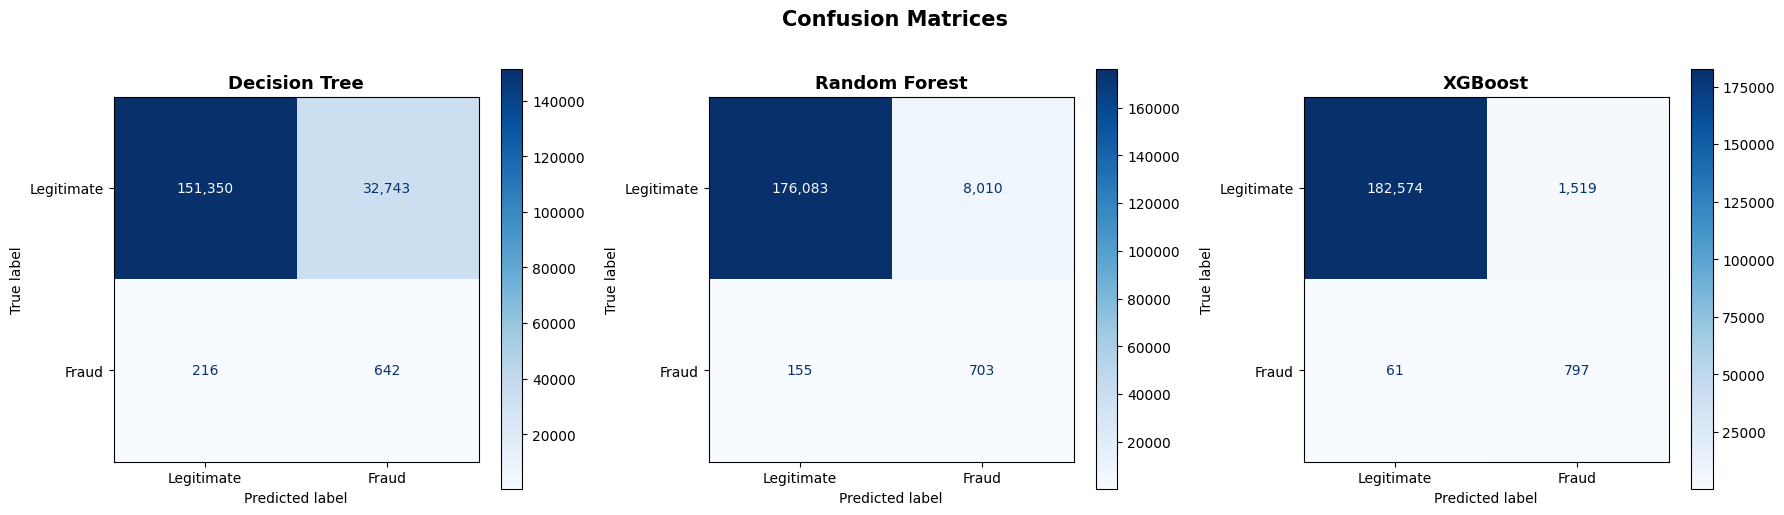

In [9]:
# ============================================================
# Confusion Matrices — side by side
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"])
    disp.plot(ax=ax, cmap="Blues", values_format=",d")
    ax.set_title(f"{name}", fontsize=13, fontweight="bold")

plt.suptitle("Confusion Matrices", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 6. Feature Importance — Top 15

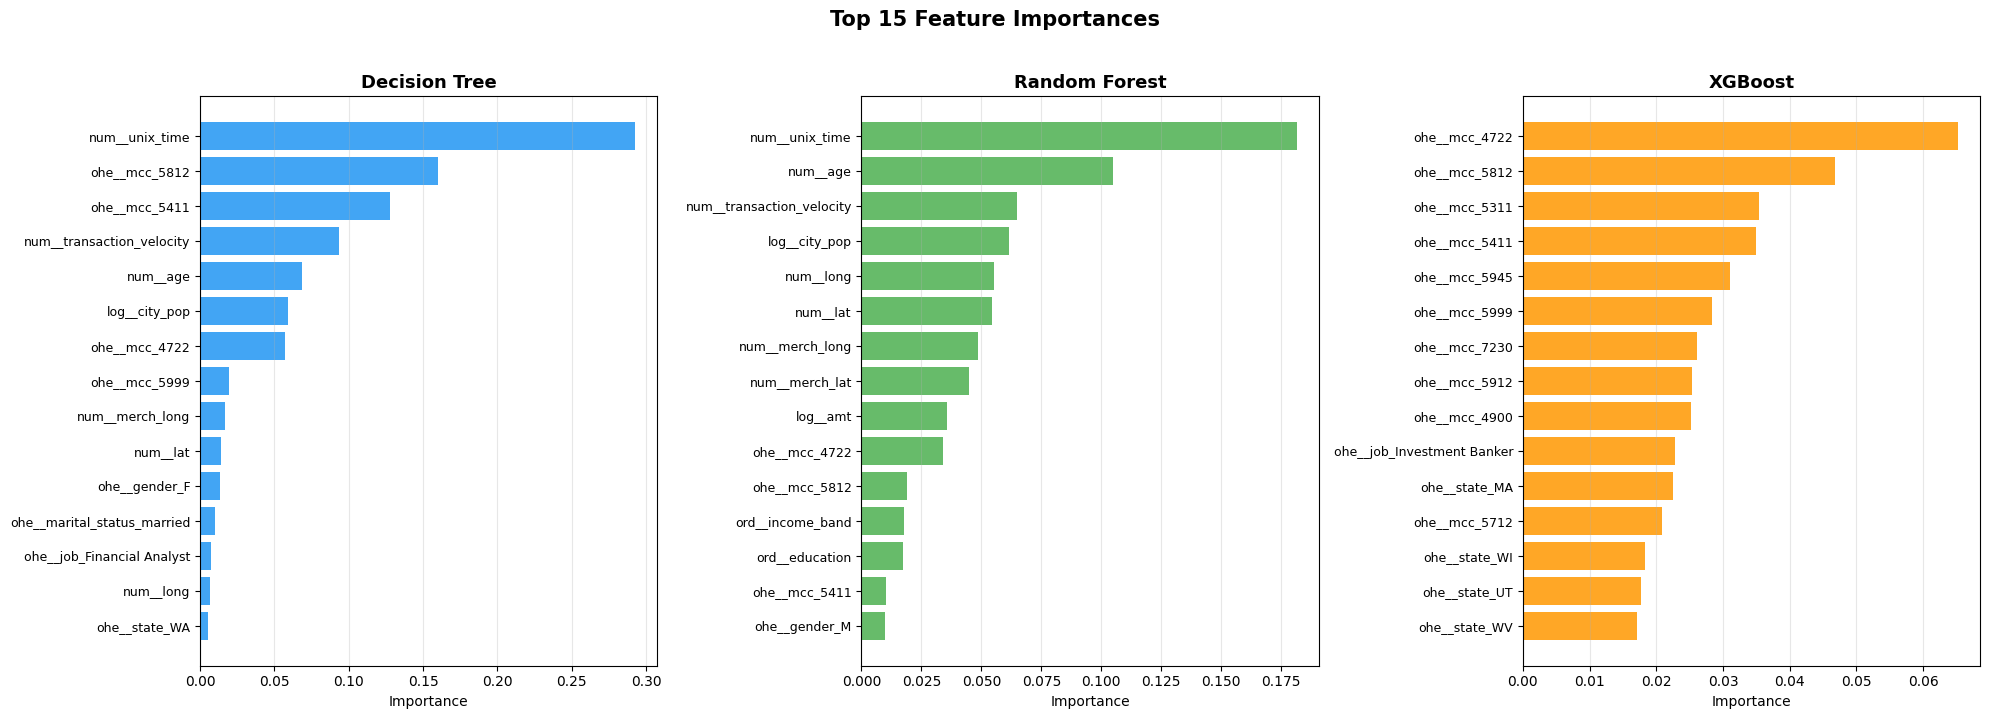

In [10]:
# ============================================================
# Feature importance for each model
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, (name, model), color in zip(axes, trained_models.items(), colors):
    importances = model.feature_importances_
    feature_names = X_train.columns

    # Get top 15
    top_idx = np.argsort(importances)[-15:]
    top_features = feature_names[top_idx]
    top_importances = importances[top_idx]

    ax.barh(range(len(top_features)), top_importances, color=color, alpha=0.85)
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features, fontsize=9)
    ax.set_xlabel("Importance")
    ax.set_title(f"{name}", fontsize=13, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Top 15 Feature Importances", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 7. Final Summary

In [11]:
# ============================================================
# Print final summary
# ============================================================

print("=" * 70)
print("FINAL MODEL COMPARISON SUMMARY")
print("=" * 70)
print(f"\nDataset: {X_train.shape[0]:,} train / {X_test.shape[0]:,} test rows")
print(f"Features: {X_train.shape[1]}")
print(f"Fraud rate: {y_test.mean():.3%}")
print()
print(results_df.to_string())
print()

# Recommend best model
best_f1_model = results_df["F1 Score"].idxmax()
best_auc_model = results_df["AUC-ROC"].idxmax()
print(f"Best F1 Score:  {best_f1_model} ({results_df.loc[best_f1_model, 'F1 Score']:.4f})")
print(f"Best AUC-ROC:   {best_auc_model} ({results_df.loc[best_auc_model, 'AUC-ROC']:.4f})")
print()

if best_f1_model == best_auc_model:
    print(f">> Recommended model: {best_f1_model} (best on both F1 and AUC-ROC)")
else:
    print(f">> {best_f1_model} has the best F1 (balanced precision/recall)")
    print(f">> {best_auc_model} has the best AUC-ROC (ranking ability)")
    print(f">> Choose based on whether you prioritize balanced detection (F1) or ranking (AUC-ROC)")

FINAL MODEL COMPARISON SUMMARY

Dataset: 739,801 train / 184,951 test rows
Features: 97
Fraud rate: 0.464%

               Accuracy  Precision    Recall  F1 Score   AUC-ROC
Model                                                           
Decision Tree  0.821796   0.019230  0.748252  0.037497  0.868131
Random Forest  0.955853   0.080684  0.819347  0.146902  0.970357
XGBoost        0.991457   0.344128  0.928904  0.502205  0.992495

Best F1 Score:  XGBoost (0.5022)
Best AUC-ROC:   XGBoost (0.9925)

>> Recommended model: XGBoost (best on both F1 and AUC-ROC)
